In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Loaded Successfully")
print("Features:", X.shape)
print("Records:", len(y))

Dataset Loaded Successfully
Features: (569, 30)
Records: 569


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [3]:
dt = DecisionTreeClassifier(
    random_state=42
)

knn = KNeighborsClassifier(
    n_neighbors=5
)

svm = SVC(
    kernel='linear',
    probability=True,
    random_state=42
)

base_models = [
    ("Decision Tree", dt),
    ("KNN", knn),
    ("SVM", svm)
]

In [4]:
stacking = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5
)

stacking.fit(X_train, y_train)

print("Stacking Model Trained Successfully")

Stacking Model Trained Successfully


In [5]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

ada.fit(X_train, y_train)

print("AdaBoost Model Trained Successfully")

AdaBoost Model Trained Successfully


In [6]:
voting = VotingClassifier(
    estimators=base_models,
    voting='hard'
)

voting.fit(X_train, y_train)

print("Voting Model Trained Successfully")

Voting Model Trained Successfully


In [7]:
models = {
    "Decision Tree": dt,
    "KNN": knn,
    "SVM": svm,
    "Stacking": stacking,
    "AdaBoost": ada,
    "Voting": voting
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred)

    recall = recall_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred)

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))


 Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


 KNN
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


 SVM
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97   

In [8]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\nPerformance Comparison:")
print(results_df.round(4))


Performance Comparison:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.9123     0.9559  0.9028    0.9286
1            KNN    0.9561     0.9589  0.9722    0.9655
2            SVM    0.9737     0.9859  0.9722    0.9790
3       Stacking    0.9825     0.9730  1.0000    0.9863
4       AdaBoost    0.9561     0.9467  0.9861    0.9660
5         Voting    0.9737     0.9726  0.9861    0.9793


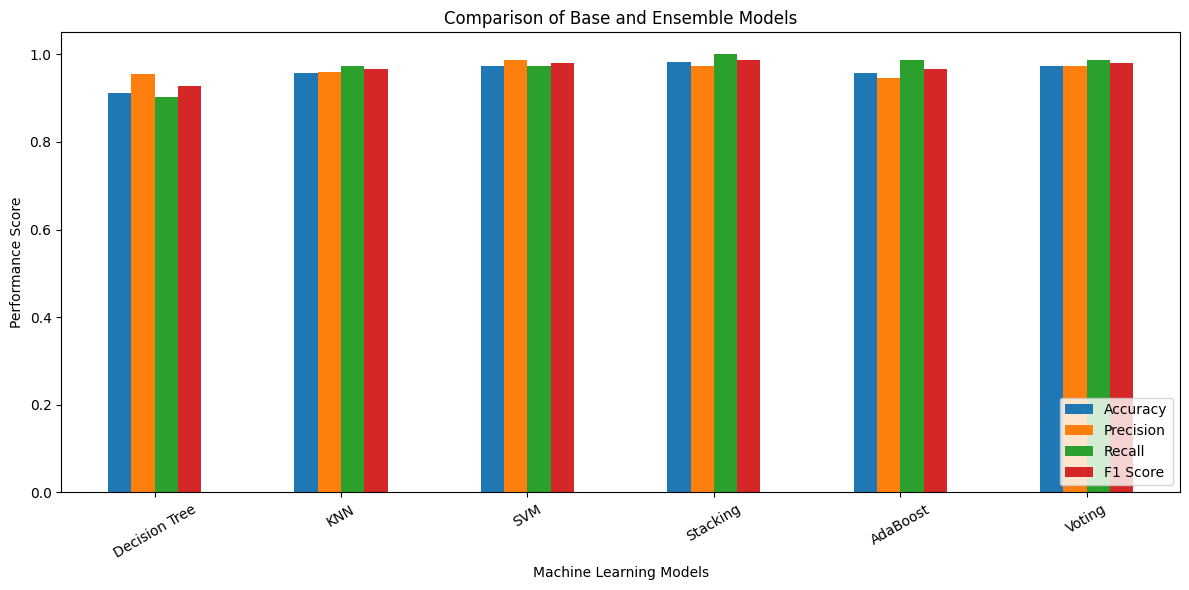

In [9]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Base and Ensemble Models")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")

plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()